# 07 - Site figures (portfolio showcase)

> **VISUALIZATION ONLY -- READS THE FULL TRAJECTORY.** This notebook reads
> every fire day (index `BUFFER_DAYS` through `n_days`) to show what each
> fire eventually did. Model inputs must never see that information
> (CLAUDE.md, "core integrity constraint"). Nothing here feeds features or
> models, and `flashpoint.site_figures` must never be imported from
> `features.py`, `rasters.py`, `cnn.py`, or notebooks 01-05. The EBM refits
> below reproduce notebook 03 Step 9's out-of-fold models only to *explain*
> the two example fires; they don't change any reported result.

Goal: one figure for the project website. It shows two fires that looked
alike over their first two days, the early-window feature that separated
them in the model's eyes, and what each fire went on to do. These are
**illustrative examples** chosen by rules fixed before the search (Step 3),
not evidence of accuracy.

Replaces notebook 05's Step 3 "sanity viz" as a showcase (that cell stays
as the crop diagnostic). Runs in the `flashpoint` kernel: h5py, duckdb,
numpy, pandas, matplotlib and interpret-core, with no torch, so
`flashpoint_mps` stays lean.

In [1]:
import sys
sys.path.insert(0, "../src")

import warnings
from pathlib import Path

import duckdb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from interpret.glassbox import ExplainableBoostingClassifier

from flashpoint.site_figures import (
    DRYNESS_RAMP, EBM_COLS, SITE_RCPARAMS, driver_funnel, driver_plane, event_from_row,
    fit_oof_ebms, load_fire_panels, plot_driver_figure, rank_pairs, scan_events,
    shape_segment_ok, tail_support,
)

warnings.filterwarnings("ignore", category=UserWarning)  # interpret's feature-type notices

DB_PATH = Path("../data/flashpoint.duckdb")
OUT_DIR = Path("../figures/site")
OUT_DIR.mkdir(parents=True, exist_ok=True)

plt.rcParams.update(SITE_RCPARAMS)
pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 30)

## Step 1: scan every fire's active-fire channel

One single-channel read per event (`read_channel_all_days`). Per event, it
records day-1 and day-2 fire pixel counts and the final footprint (every
pixel ever detected). It also flags fallback-center events (zero early
fire pixels), edge clipping (the CNN's 128 px early crop, or the final
footprint touching the raster border), and gap days (zero detections
between the first and last detection).

In [2]:
con = duckdb.connect(str(DB_PATH), read_only=True)
events_df = con.execute("SELECT * FROM events").df()
outcomes_df = con.execute(
    "SELECT event_id, max_area_ha, duration_days, severity_class FROM event_outcomes"
).df()

scan = scan_events(events_df)
cands = scan.merge(outcomes_df, on="event_id").merge(
    events_df[["event_id", "year", "n_days"]], on="event_id"
)
cands["escalates"] = (cands["severity_class"] > 0).astype(int)

print(f"{len(cands)} events scanned")
print(f"fallback center (no day-1/2 fire): {cands['fallback_center'].mean():.1%}")
print(f"early crop edge-clipped:           {cands['early_crop_clipped'].mean():.1%}")
print(f"footprint touches raster edge:     {cands['footprint_touches_edge'].mean():.1%}")
print(f"has >=1 zero-detection gap day:    {(cands['gap_days'] > 0).mean():.1%}")

  0%|          | 0/607 [00:00<?, ?it/s]

  1%|▏         | 9/607 [00:00<00:06, 88.71it/s]

  3%|▎         | 21/607 [00:00<00:05, 103.22it/s]

  5%|▌         | 32/607 [00:00<00:05, 104.44it/s]

  8%|▊         | 47/607 [00:00<00:04, 118.89it/s]

...

 95%|█████████▍| 576/607 [00:04<00:00, 92.20it/s]

 97%|█████████▋| 590/607 [00:05<00:00, 103.11it/s]

 99%|█████████▉| 602/607 [00:05<00:00, 107.13it/s]

100%|██████████| 607/607 [00:05<00:00, 116.70it/s]

607 events scanned
fallback center (no day-1/2 fire): 25.7%
early crop edge-clipped:           11.4%
footprint touches raster edge:     5.3%
has >=1 zero-detection gap day:    56.8%


## Step 2: look-alike pairs (stage-1 rules)

`rank_pairs` keeps fires with detections on both day 1 and day 2 (at
least 6 early pixels). It drops fallback-center events, edge clipping and
gap days, caps the escalated footprint box at 160 px, and requires the
two-day unions to be within 1.25x of each other. Score = log(footprint
growth ratio), penalized by day-1, day-2 and union mismatch.

In [3]:
pairs = rank_pairs(cands)
print(f"{len(pairs)} look-alike pairs")

66 look-alike pairs


## Step 3: the out-of-fold EBM, and why the first pair was dropped

Notebook 03 Step 9's binary EBM (base+topo, 15 features,
`interactions=0`, `random_state=0`) is refit per LOYO fold. Each event's
probability and per-term contributions come from the model that held out
its year. Global importances come from the same config fit on all events.

The first showcase pair (stage 1: escalated `fire_24461789`, contained
`fire_23159657`) was dropped because of the next cell's finding. The
contained fire was called correctly only by a coin-flip margin
(P = 0.478). The term that separated the pair most was **aspect (mean
sin)**. The contained fire's value sits about 2.4 standard deviations into
the tail, where only 5 fires in its fold's training data are as extreme.
The shape function there is close to a cliff: the score drops from about
-0.2 to about -0.8 at -0.12, and that one step carries 48% of the score
change between the two fires. That is just under the 50% cliff threshold
adopted below, so under the formal rules this pair fails on margin (rule 2)
and tail support (rule 6), not on rule 5. Either way, it is a thin-data
artifact, not a driver to showcase.

In [4]:
train_df = con.execute("""
    SELECT e.year, f.*, o.severity_class
    FROM early_features f
    JOIN events e ON e.event_id = f.event_id
    JOIN event_outcomes o ON o.event_id = f.event_id
""").df()
train_df["escalates"] = (train_df["severity_class"] > 0).astype(int)

fold_models, oof = fit_oof_ebms(train_df)
oof.index = train_df["event_id"]
print(f"pooled OOF accuracy: {((oof['p_escalate'] >= 0.5).to_numpy() == train_df['escalates']).mean():.3f}")

ebm_all = ExplainableBoostingClassifier(interactions=0, random_state=0)
ebm_all.fit(train_df[EBM_COLS], train_df["escalates"])
global_imp = pd.Series(ebm_all.term_importances(), ebm_all.term_names_).sort_values(ascending=False)
global_rank = pd.Series(np.arange(1, len(global_imp) + 1), global_imp.index)
print("\nglobal term importances (binary EBM, all events):")
print(global_imp.round(3).to_string())

# The stage-1 pair's aspect finding.
feats = train_df.set_index("event_id")
v = feats.loc["fire_23159657", "aspect_sin_mean"]
asp = train_df["aspect_sin_mean"]
m19 = fold_models[2019]
tr19 = train_df.loc[train_df["year"] != 2019, "aspect_sin_mean"]
print(f"\nfire_23159657: OOF P = {oof.loc['fire_23159657', 'p_escalate']:.3f}, "
      f"aspect_sin_mean = {v:.3f} (z = {(v - asp.mean()) / asp.std():.1f}), "
      f"contribution {oof.loc['fire_23159657', 'aspect_sin_mean']:+.3f}")
print(f"training fires (2019 fold) as extreme or more: {tail_support(tr19, v)}")
print("2019-fold shape between the two stage-1 fires:",
      shape_segment_ok(m19, "aspect_sin_mean", v, feats.loc["fire_24461789", "aspect_sin_mean"]))

pooled OOF accuracy: 0.842



global term importances (binary EBM, all events):
fire_extent_ha             1.091
slope_mean                 0.401
erc_mean                   0.346
max_temp_max               0.328
aspect_sin_mean            0.205
slope_max                  0.136
wind_speed_mean            0.133
min_temp_min               0.129
pdsi_mean                  0.098
aspect_cos_mean            0.074
wind_direction_sin_mean    0.070
wind_speed_max             0.063
humidity_min               0.041
wind_direction_cos_mean    0.035
elevation_mean             0.017

fire_23159657: OOF P = 0.478, aspect_sin_mean = -0.197 (z = -2.4), contribution -1.055
training fires (2019 fold) as extreme or more: 5
2019-fold shape between the two stage-1 fires: {'net': 1.111131198684317, 'reversal_frac': 0.0, 'max_step_frac': 0.47995885459742654, 'ok': True}


### Selection rules (fixed before searching)

These rules were fixed before looking at any results and were not loosened
afterward:

1. **Look-alike:** the stage-1 rules above, plus both footprint boxes
   <= 64 px (24 km) so the fires read at website size.
2. **Called correctly out of fold:** both fires, each at least 0.1 from the
   0.5 threshold.
3. **Mappable driver:** the term with the largest contribution gap
   (excluding fire size) has a plain-language raster: slope, ERC or a
   weather layer. Aspect, elevation and wind-direction components don't
   count. It must favor the escalated fire.
4. **Matters globally:** that term is in the top 5 global importances.
5. **Smooth shape function:** between the two fires' values, in both
   fires' fold models, movement against the overall direction is <= 10% of
   the net change, and no single bin step is > 50% of it.
6. **Tail support:** each fire's value has at least 20 training fires as
   extreme or more.
7. **Visible difference:** the two box means differ by at least 25% of the
   shared color range (2nd-98th percentile of both boxes' pixels).

**Run 1, as fixed:** no pair passed. No compact look-alike pair has a
contained fire called correctly with margin. The compact contained fires
score 0.48-0.72, the same false-alarm weakness Step 9 documents.

**Run 2, compactness cap dropped (an explicit decision after run 1):** 5
pairs pass. **All 5 are driven by fuel dryness (ERC).** The legibility
problem the cap was guarding against is handled by the layout instead.
Days 1-2 get their own zoom, shared across rows. The ERC and footprint
panels share a second, wider 24 km window centered on each fire's early
pixels. A first draft showed the whole raster box (about 130 km) there,
but at 600 px the escalated fire's growth was invisible.

In [5]:
shortlist_capped, counts_capped = driver_funnel(
    pairs, oof, fold_models, train_df, global_rank, events_df, compact_px=64)
shortlist, counts = driver_funnel(
    pairs, oof, fold_models, train_df, global_rank, events_df, compact_px=None)

funnel = pd.DataFrame({"run 1 (64 px cap)": pd.Series(counts_capped),
                       "run 2 (no cap)": pd.Series(counts)}).reindex(list(counts_capped))
print(funnel.map(lambda v: "--" if pd.isna(v) else f"{v:.0f}").to_string())
print("\nrun-2 drivers:", shortlist["driver"].value_counts().to_dict())

                                       run 1 (64 px cap) run 2 (no cap)
look-alike pairs (stage-1 rules)                      66             66
both footprint boxes <= 64 px                         15             --
both OOF-correct by >= 0.1                             0             18
top non-size term is mappable                          0             16
...and favors the escalated fire                       0             15
driver in global top 5                                 0              7
shape monotonic, no cliff                              0              6
>= 20 training fires as extreme                        0              5
box means differ >= 25% of color range                 0              5

run-2 drivers: {'erc_mean': 5}


/Users/pmacias/Dropbox/flashpoint/notebooks/../src/flashpoint/site_figures.py:562: RuntimeWarning: Mean of empty slice
  plane = _SCALAR_REDUCE[reduce](stack, axis=0)


## Step 4: the pick

Choose among the 5 survivors by how well the early growth matches **day
by day**: the sum of |log(day-d pixel ratio)| over days 1 and 2, the same
mismatch term `rank_pairs` uses. Out-of-fold P margin breaks ties.

In [6]:
sl = shortlist.copy()
sl["day_mismatch"] = sum(
    np.abs(np.log(sl[f"early_d{d}_px_esc"] / sl[f"early_d{d}_px_con"])) for d in (1, 2)
)
sl["p_margin"] = np.minimum(sl["p_esc"] - 0.5, 0.5 - sl["p_con"])
sl.sort_values("day_mismatch")[[
    "event_id_esc", "event_id_con", "early_d1_px_esc", "early_d1_px_con",
    "early_d2_px_esc", "early_d2_px_con", "day_mismatch", "p_esc", "p_con", "p_margin",
    "footprint_px_esc", "footprint_px_con", "max_area_ha_esc", "max_area_ha_con",
    "val_esc", "val_con", "contrib_esc", "contrib_con", "min_support", "visible_frac",
]].round(3)

,event_id_esc,event_id_con,early_d1_px_esc,early_d1_px_con,early_d2_px_esc,early_d2_px_con,day_mismatch,p_esc,p_con,p_margin,footprint_px_esc,footprint_px_con,max_area_ha_esc,max_area_ha_con,val_esc,val_con,contrib_esc,contrib_con,min_support,visible_frac
2,fire_24104639,fire_25088018,111,56,30,73,1.573,0.953,0.168,0.332,133,191,1560.938,1026.562,92.432,51.258,0.511,-0.737,20,0.735
1,fire_24104658,fire_25088018,13,56,90,73,1.670,0.934,0.168,0.332,378,191,3459.375,1026.562,83.440,51.258,0.492,-0.737,59,0.692
3,fire_22141243,fire_25088018,10,56,118,73,2.203,0.983,0.168,0.332,244,191,1659.375,1026.562,77.134,51.258,0.284,-0.737,60,0.551
0,fire_24103557,fire_23300744,28,41,35,4,2.550,0.855,0.374,0.126,2302,79,8901.562,576.562,92.521,58.079,0.511,-0.402,20,0.542
4,fire_24103582,fire_23300744,4,41,38,4,4.579,0.964,0.374,0.126,802,79,3853.125,576.562,89.449,58.079,0.515,-0.402,31,0.546


**Picked: escalated `fire_24104658`, contained `fire_25088018`.** This
is the second-best day-by-day match (1.67 vs. 1.57). On the mismatch
metric alone, and on the P tiebreak, `fire_24104639` would win. Its
cumulative footprint, though, is *smaller* than the contained fire's
(133 vs. 191 px), so the "what happened" panel would contradict its
"escalated" label. Its peak (1,561 ha) also barely clears the 1,392 ha
tier boundary. So this is a deliberate override of the strict
day-by-day ranking: that pair contradicts what the figure claims, which
is a different problem from looking worse. The picked pair matches
on day 2 (90 vs. 73 px) but not day 1 (13 vs. 56). The escalated fire
started smaller.

## Step 5: the figure

**The ERC number.** `erc_mean` in `features.py` is
`np.nanmean(energy_release_component)` over the early window: days 1 and
2, *every pixel of the event's raster box*. It is not a value near the
fire. The map shows the per-pixel mean over those two days. Averaged over
the whole box, that plane equals the scalar the EBM used; the cell asserts
this against the stored feature. The panel crops the map to the same
24 km window as the footprint, so the annotated "mean over mapped area"
is the **whole-box** value the model used, not the average of the visible
crop. The box itself is drawn around
the fire's eventual footprint, a geometry caveat the tabular features
already carry (`rasters.py` docstring).

**Cumulative vs. peak.** The right column is cumulative: every pixel
ever detected over the whole fire. "Peak day" (`max_area_ha`, the label
basis) is the largest single day's active-fire area, so the two differ
whenever the fire moves.

`MAP_SIDE = 64` (px, 24 km) is the shared window for the ERC and
footprint panels. Detections outside it are counted in the footprint
panel. `MAP_SIDE = None` shows the whole raster box instead.

fire_24104658: ERC box mean 83.44 (contribution +0.492), OOF P 0.934, footprint 378 px, detected span 7 d, DB duration_days 15
fire_25088018: ERC box mean 51.26 (contribution -0.737), OOF P 0.168, footprint 191 px, detected span 7 d, DB duration_days 14


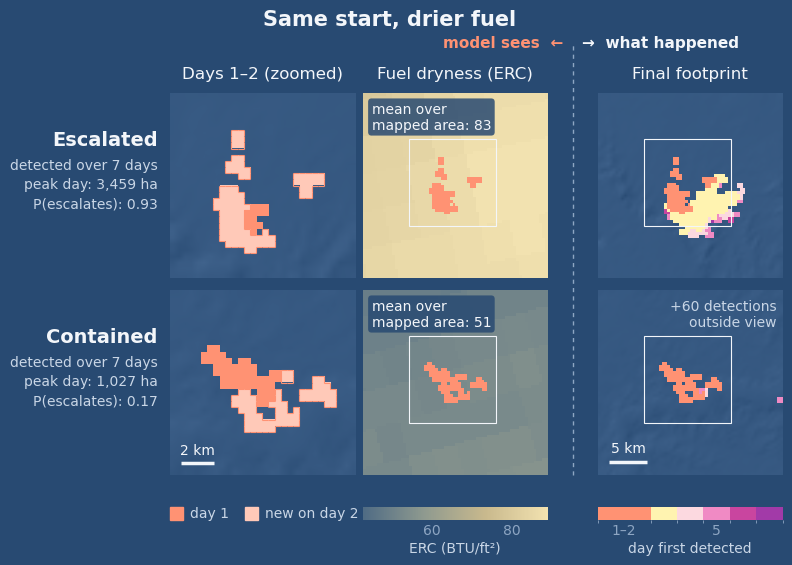

In [7]:
PICK = [("fire_24104658", "Escalated"), ("fire_25088018", "Contained")]
DRIVER = "erc_mean"
MAP_SIDE = 64

meta = events_df.merge(outcomes_df, on="event_id").set_index("event_id", drop=False)
rows = []
for eid, label in PICK:
    r = meta.loc[eid]
    event = event_from_row(r)
    panels = load_fire_panels(event)
    plane, scalar = driver_plane(event, DRIVER)
    assert np.isclose(scalar, feats.loc[eid, DRIVER], rtol=1e-4), (scalar, feats.loc[eid, DRIVER])
    p = oof.loc[eid, "p_escalate"]
    panels.update(
        label=label, driver_plane=plane, driver_scalar=scalar, p_escalate=p,
        sublines=[f"detected over {panels['detected_span_days']} days",
                  f"peak day: {r.max_area_ha:,.0f} ha",
                  f"P(escalates): {p:.2f}"],
    )
    rows.append(panels)
    print(f"{eid}: ERC box mean {scalar:.2f} (contribution {oof.loc[eid, DRIVER]:+.3f}), "
          f"OOF P {p:.3f}, footprint {panels['footprint_px']} px, "
          f"detected span {panels['detected_span_days']} d, DB duration_days {r.duration_days}")

fig = plot_driver_figure(
    rows, driver_title="Fuel dryness (ERC)", driver_unit="ERC (BTU/ft²)",
    driver_cmap_colors=DRYNESS_RAMP, title="Same start, drier fuel",
    map_side=MAP_SIDE,
)
fig.savefig(OUT_DIR / "flashpoint_growth.png", dpi=200)
fig.savefig(OUT_DIR / "flashpoint_growth.pdf")
plt.show()

## Step 6: readability at display size

The site shows this about 600 px wide on desktop and 350 px on mobile.

(1600, 1200)


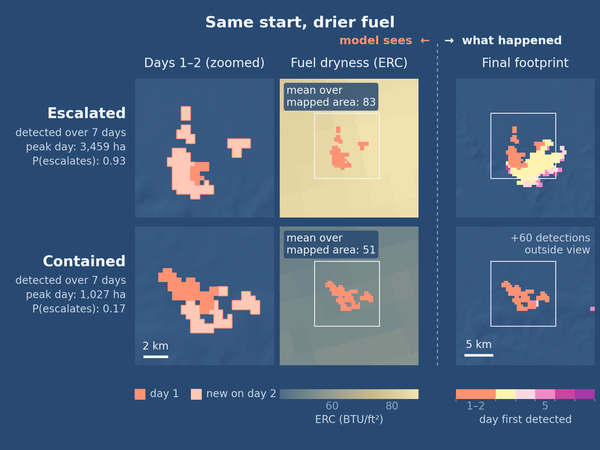

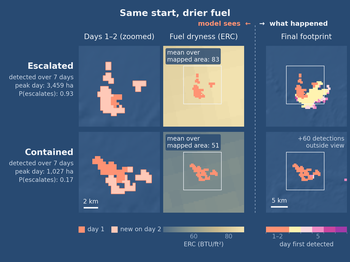

In [8]:
from PIL import Image

img = Image.open(OUT_DIR / "flashpoint_growth.png")
print(img.size)
for width in (600, 350):
    display(img.resize((width, round(width * img.height / img.width)), Image.LANCZOS))

## Website caption

Two illustrative fires that looked alike over their first two days of
satellite detections; the one that escalated was burning in much drier
fuel (ERC 83 vs. 51), a feature the model weights heavily overall. The
model sees only the box-average value, not the map, and the pair was
chosen by rules fixed in advance.

## Caveats

- The two fires match on day 2 (90 vs. 73 px) but not on day 1 (13 vs.
  56 px). The escalated fire started smaller.
- The contained fire's 191 cumulative pixels include about 60 scattered
  detections up to tens of km from the main fire. Part of its footprint
  is probably separate hot spots, not one spreading front.
- ERC is gridded at about 4 km and resampled to 375 m, which is why the
  map looks blocky.
- DB `duration_days` is the stored sequence length (including 4
  pre-ignition buffer days), so the row labels use the first-to-last
  detection span instead.